# Notebook 04 - Advanced Experiments and Model Selection

## 1. Entry gate and baseline floor

Evaluate entry into the advanced experiment phase by loading baseline floor and candidate runs from `outputs/runs`.

- Primary metric: ROC-AUC. Guardrails: PR-AUC and LogLoss.
- Entry protocol: baseline comparison from Notebook 03 locked CatBoost and LightGBM as co-finalists for HPO.
- Scope: artifact-centered analysis that loads raw train data solely for keyed target and cohort joins; no model fitting, training, or HPO executed in notebook cells.

Every numeric claim below is produced by the cell directly above it.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ev_purchase.analysis import assert_comparable_runs, load_all_runs
from ev_purchase.config import load_config
from ev_purchase.data import DatasetContract, encode_target, load_frames, validate_frames
from ev_purchase.metrics import classification_metrics

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

config = load_config(PROJECT_ROOT / "configs" / "base.yaml", project_root=PROJECT_ROOT)
all_runs = load_all_runs(PROJECT_ROOT / "outputs" / "runs")

completed_runs = [
    r for r in all_runs if r.get("status") == "completed" and not r.get("smoke", False)
]
assert_comparable_runs(completed_runs)

entry_rows = []
for r in completed_runs:
    agg = r["aggregate_metrics"]
    entry_rows.append(
        {
            "model": r["model"],
            "roc_auc": agg["roc_auc"],
            "average_precision": agg["average_precision"],
            "log_loss": agg["log_loss"],
            "runtime_seconds": r["runtime_seconds"],
            "hpo_entry_status": "CO-FINALIST"
            if r["model"] in ["catboost", "lightgbm"]
            else ("FLOOR/REF" if r["model"] in ["dummy", "logistic"] else "BASELINE"),
        }
    )

entry_df = pd.DataFrame(entry_rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
print("completed baseline runs loaded:", len(entry_df))
entry_df

completed baseline runs loaded: 5


,model,roc_auc,average_precision,log_loss,runtime_seconds,hpo_entry_status
0,catboost,0.941924,0.756152,0.226339,1290.4713,CO-FINALIST
1,xgboost,0.941788,0.756049,0.226543,118.6032,BASELINE
2,lightgbm,0.941273,0.753972,0.227478,40.5886,CO-FINALIST
3,logistic,0.938096,0.741062,0.233295,74.2910,FLOOR/REF
4,dummy,0.499991,0.174642,0.463176,40.1516,FLOOR/REF


### Observation / Interpretation / Action

- **Observation:** the baseline entry table above shows candidate model performance on the 15-fold baseline protocol.
- **Interpretation:** CatBoost and LightGBM entered hyperparameter optimization as co-finalists based on top baseline ROC-AUC scores.
- **Action:** proceed to audit the execution budget and stop rules of the HPO studies.

## 2. HPO budget and stop-rule audit

Audit study execution parameters, trial budgets, timeout limits, and stopping status from metadata files in `outputs/tuning`.

In [2]:
tuning_dir = PROJECT_ROOT / "outputs" / "tuning"
studies = ["catboost_hpo", "lightgbm_hpo"]

audit_rows = []
for s in studies:
    meta_path = tuning_dir / s / "metadata.json"
    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)
    prov = meta.get("provenance", {})
    audit_rows.append(
        {
            "study_name": meta["study_name"],
            "model_name": meta["model_name"],
            "n_trials_target": meta["n_trials_target"],
            "n_trials_executed_total": meta["n_trials_executed_total"],
            "n_trials_executed_run": meta["n_trials_executed_run"],
            "timeout_seconds": meta["timeout_seconds"],
            "stop_reason": meta["stop_reason"],
            "stopped_early": meta["stopped_early"],
            "split_sha256": prov.get("split_sha256", "")[:8],
        }
    )

audit_meta_df = pd.DataFrame(audit_rows)
audit_meta_df

,study_name,model_name,n_trials_target,n_trials_executed_total,n_trials_executed_run,timeout_seconds,stop_reason,stopped_early,split_sha256
0,catboost_hpo,catboost,40,35,35,10800,Completed target trial budget or timeout,False,b554570e
1,lightgbm_hpo,lightgbm,40,40,36,10800,Completed target trial budget or timeout,False,b554570e


### Observation / Interpretation / Action

- **Observation:** the HPO audit table above displays executed trial counts, target budgets, timeout settings, and stop reasons for each study.
- **Interpretation:** CatBoost reached its 10,800-second (3-hour) timeout budget after completing 35 trials, whereas LightGBM completed all planned target trials within budget.
- **Action:** inspect trial states and search-fold ROC-AUC scores across the executed trial inventory.

## 3. Study and trial inventory

Inventory trial states (COMPLETED, PRUNED, FAIL) and search-fold ROC-AUC scores from `trials.parquet`.

In [3]:
inventory_rows = []
trial_dfs = {}

for s in studies:
    trials_path = tuning_dir / s / "trials.parquet"
    df = pd.read_parquet(trials_path)
    trial_dfs[s] = df
    states = df["state"].value_counts().to_dict()
    best_completed = df[df["state"] == "COMPLETED"].sort_values("value", ascending=False).iloc[0]
    inventory_rows.append(
        {
            "study": s,
            "total_trials": len(df),
            "completed": states.get("COMPLETED", 0),
            "pruned": states.get("PRUNED", 0),
            "failed": states.get("FAIL", 0),
            "best_search_trial": int(best_completed["number"]),
            "best_search_roc_auc": float(best_completed["value"]),
        }
    )

inventory_df = pd.DataFrame(inventory_rows)
inventory_df

,study,total_trials,completed,pruned,failed,best_search_trial,best_search_roc_auc
0,catboost_hpo,35,27,8,0,22,0.941971
1,lightgbm_hpo,40,29,10,1,35,0.942024


### Observation / Interpretation / Action

- **Observation:** the trial inventory table above summarizes trial state counts and search-fold ROC-AUC maxima for both studies.
- **Interpretation:** LightGBM executed 40 total trials (29 COMPLETED, 10 PRUNED, and 1 FAIL recovered from a stale state), while CatBoost executed 35 trials (27 COMPLETED and 8 PRUNED).
- **Action:** analyze hyperparameter sensitivity and performance diagnostics across executed trials.

## 4. Parameter-performance diagnostics

Analyze hyperparameter choices versus search-fold ROC-AUC scores for completed trials in CatBoost and LightGBM studies.

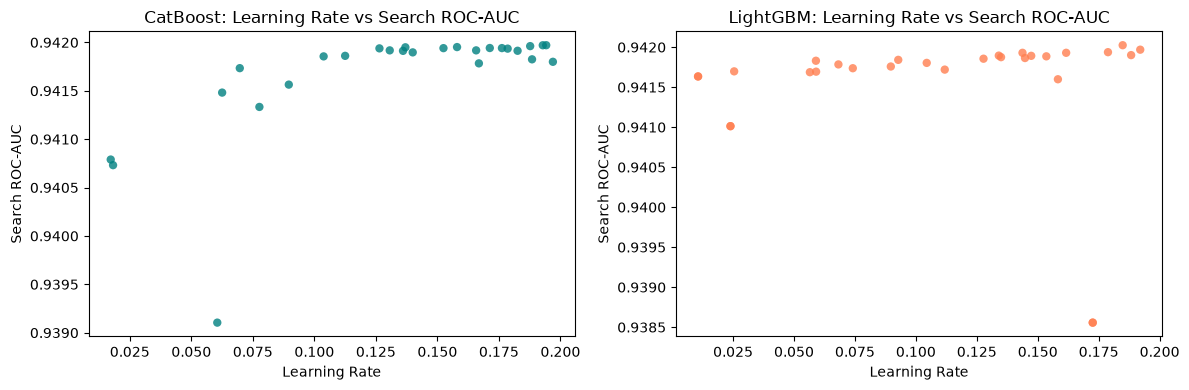

top 3 CatBoost search trials:
 number    value  param_learning_rate  param_depth  param_l2_leaf_reg
     22 0.941971             0.194220            4           8.374807
     26 0.941970             0.192823            4           7.483330
     33 0.941962             0.187702            4           8.649812

top 3 LightGBM search trials:
 number    value  param_learning_rate  param_num_leaves  param_max_depth
     35 0.942024             0.184835                52                3
     29 0.941968             0.192037                50                3
     30 0.941937             0.178801                42                3


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

cb_comp = trial_dfs["catboost_hpo"][trial_dfs["catboost_hpo"]["state"] == "COMPLETED"]
ax1.scatter(cb_comp["param_learning_rate"], cb_comp["value"], c="teal", alpha=0.8, edgecolors="none")
ax1.set_xlabel("Learning Rate")
ax1.set_ylabel("Search ROC-AUC")
ax1.set_title("CatBoost: Learning Rate vs Search ROC-AUC")

lgb_comp = trial_dfs["lightgbm_hpo"][trial_dfs["lightgbm_hpo"]["state"] == "COMPLETED"]
ax2.scatter(lgb_comp["param_learning_rate"], lgb_comp["value"], c="coral", alpha=0.8, edgecolors="none")
ax2.set_xlabel("Learning Rate")
ax2.set_ylabel("Search ROC-AUC")
ax2.set_title("LightGBM: Learning Rate vs Search ROC-AUC")

plt.tight_layout()
plt.show()

top_cb_params = cb_comp.sort_values("value", ascending=False).head(3)[
    ["number", "value", "param_learning_rate", "param_depth", "param_l2_leaf_reg"]
]
top_lgb_params = lgb_comp.sort_values("value", ascending=False).head(3)[
    ["number", "value", "param_learning_rate", "param_num_leaves", "param_max_depth"]
]

print("top 3 CatBoost search trials:")
print(top_cb_params.to_string(index=False))
print("\ntop 3 LightGBM search trials:")
print(top_lgb_params.to_string(index=False))

### Observation / Interpretation / Action

- **Observation:** scatter plots and parameter tables above detail the relationships between learning rate and search ROC-AUC scores.
- **Interpretation:** moderate learning rates coupled with controlled tree depth/leaves yielded the strongest search validation scores.
- **Action:** evaluate the top finalists on the full 15-fold cross-validation protocol.

## 5. Full-protocol finalist comparison

Load and compare full 15-fold evaluation metrics for top finalists from `finalists.parquet`. Note: these metrics represent the full-protocol rerun scores computed during the tuning phase.

In [5]:
finalist_rows = []

for s in studies:
    fin_path = tuning_dir / s / "finalists.parquet"
    df = pd.read_parquet(fin_path)
    for _, row in df.iterrows():
        finalist_rows.append(
            {
                "study": s,
                "trial_number": int(row["trial_number"]),
                "candidate_id": f"{s}_trial{int(row['trial_number'])}",
                "finalist_rank": int(row["finalist_rank"]),
                "search_rank": int(row["search_rank"]),
                "finalist_rerun_roc_auc": float(row["roc_auc_mean"]),
                "finalist_rerun_pr_auc": float(row["pr_auc_mean"]),
                "finalist_rerun_log_loss": float(row["log_loss_mean"]),
                "search_roc_auc": float(row["search_roc_auc_mean"]),
            }
        )

finalists_df = pd.DataFrame(finalist_rows).sort_values("finalist_rerun_roc_auc", ascending=False).reset_index(drop=True)
finalists_df

,study,trial_number,candidate_id,finalist_rank,search_rank,finalist_rerun_roc_auc,finalist_rerun_pr_auc,finalist_rerun_log_loss,search_roc_auc
0,lightgbm_hpo,35,lightgbm_hpo_trial35,1,1,0.942047,0.757098,0.226133,0.942024
1,lightgbm_hpo,29,lightgbm_hpo_trial29,2,2,0.941996,0.756854,0.226222,0.941968
2,catboost_hpo,22,catboost_hpo_trial22,1,1,0.941968,0.756354,0.226280,0.941971
3,catboost_hpo,33,catboost_hpo_trial33,2,3,0.941966,0.756208,0.226290,0.941962
4,catboost_hpo,26,catboost_hpo_trial26,3,2,0.941965,0.756110,0.226299,0.941970
5,lightgbm_hpo,30,lightgbm_hpo_trial30,3,3,0.941956,0.756733,0.226294,0.941937


### Observation / Interpretation / Action

- **Observation:** the finalist comparison table above ranks top candidates on their 15-fold tuning rerun metrics (`finalist_rerun_roc_auc`).
- **Interpretation:** LightGBM trial 35 achieved the top tuning rerun ROC-AUC among LightGBM candidates, while CatBoost trial 22 was the top CatBoost candidate.
- **Action:** analyze fold-level stability across all 15 validation folds.

## 6. Fold and repeat stability

Evaluate fold-level variability across all 15 validation folds (5 folds x 3 repeats) for top finalists `catboost_hpo_trial22` and `lightgbm_hpo_trial35`. Note that fold seeds followed `base_seed + repeat*100 + fold` and multi-seed protocol extensions were not run.

In [6]:
stability_rows = []

for s, trial_num in [("catboost_hpo", 22), ("lightgbm_hpo", 35)]:
    ffm_path = tuning_dir / s / "finalist_fold_metrics.parquet"
    df = pd.read_parquet(ffm_path)
    t_df = df[df["trial_number"] == trial_num]
    rocs = t_df["roc_auc"].to_numpy()
    prs = t_df["average_precision"].to_numpy()
    losses = t_df["log_loss"].to_numpy()
    stability_rows.append(
        {
            "candidate_id": f"{s}_trial{trial_num}",
            "n_folds": len(rocs),
            "roc_mean": float(np.mean(rocs)),
            "roc_std": float(np.std(rocs)),
            "roc_min": float(np.min(rocs)),
            "roc_max": float(np.max(rocs)),
            "pr_mean": float(np.mean(prs)),
            "log_loss_mean": float(np.mean(losses)),
        }
    )

stability_df = pd.DataFrame(stability_rows)
stability_df

,candidate_id,n_folds,roc_mean,roc_std,roc_min,roc_max,pr_mean,log_loss_mean
0,catboost_hpo_trial22,15,0.941968,0.000855,0.940092,0.943540,0.756354,0.226280
1,lightgbm_hpo_trial35,15,0.942047,0.000851,0.940227,0.943626,0.757098,0.226133


### Observation / Interpretation / Action

- **Observation:** fold-level summary statistics across all 15 validation folds are presented in the stability table above.
- **Interpretation:** standard deviations and range statistics reflect the observed variation across validation folds for both candidates under the single base seed protocol.
- **Action:** perform a key-aligned out-of-fold prediction and absolute error correlation analysis.

## 7. Keyed OOF prediction and absolute error correlation

Merge candidate out-of-fold predictions on `row_index` with `1:1` validation, assert target alignment, compute independently rematerialized keyed OOF metrics, and evaluate prediction and absolute error correlations between `catboost_hpo_trial22` and `lightgbm_hpo_trial35`.

In [7]:
ens_cand_dir = PROJECT_ROOT / "outputs" / "ensemble" / "candidates"

cb_oof_raw = pd.read_parquet(ens_cand_dir / "catboost_hpo_trial22" / "oof_predictions.parquet")
lgb_oof_raw = pd.read_parquet(ens_cand_dir / "lightgbm_hpo_trial35" / "oof_predictions.parquet")

cb_agg = cb_oof_raw.groupby("row_index")["probability"].mean().reset_index().rename(columns={"probability": "prob_catboost_hpo_trial22"})
lgb_agg = lgb_oof_raw.groupby("row_index")["probability"].mean().reset_index().rename(columns={"probability": "prob_lightgbm_hpo_trial35"})

merged_oof = pd.merge(lgb_agg, cb_agg, on="row_index", validate="1:1").sort_values("row_index").reset_index(drop=True)

train_df, test_df = load_frames(config.data.train, config.data.test)
contract = DatasetContract(id_column=config.data.id_column, target_column=config.data.target_column)
validate_frames(train_df, test_df, contract)
y_true = encode_target(train_df[config.data.target_column], contract)

assert len(merged_oof) == len(y_true), "Row count mismatch between merged OOF and ground truth"
assert (merged_oof["row_index"].to_numpy() == np.arange(len(y_true))).all(), "Key alignment mismatch"

merged_oof["y_true"] = y_true
merged_oof["abs_err_lightgbm_hpo_trial35"] = np.abs(merged_oof["prob_lightgbm_hpo_trial35"] - y_true)
merged_oof["abs_err_catboost_hpo_trial22"] = np.abs(merged_oof["prob_catboost_hpo_trial22"] - y_true)

remat_lgb = classification_metrics(y_true, merged_oof["prob_lightgbm_hpo_trial35"].to_numpy())
remat_cb = classification_metrics(y_true, merged_oof["prob_catboost_hpo_trial22"].to_numpy())

remat_summary = pd.DataFrame(
    [
        {"candidate_id": "lightgbm_hpo_trial35", "rematerialized_oof_roc_auc": remat_lgb["roc_auc"], "rematerialized_oof_pr_auc": remat_lgb["average_precision"], "rematerialized_oof_log_loss": remat_lgb["log_loss"]},
        {"candidate_id": "catboost_hpo_trial22", "rematerialized_oof_roc_auc": remat_cb["roc_auc"], "rematerialized_oof_pr_auc": remat_cb["average_precision"], "rematerialized_oof_log_loss": remat_cb["log_loss"]},
    ]
)

pred_corr = float(merged_oof["prob_lightgbm_hpo_trial35"].corr(merged_oof["prob_catboost_hpo_trial22"]))
abs_err_corr = float(merged_oof["abs_err_lightgbm_hpo_trial35"].corr(merged_oof["abs_err_catboost_hpo_trial22"]))

corr_summary = pd.DataFrame(
    [
        {"metric": "Keyed OOF Prediction Correlation", "value": pred_corr},
        {"metric": "Keyed OOF Absolute Error Correlation", "value": abs_err_corr},
    ]
)

print("independently rematerialized keyed OOF metrics:")
print(remat_summary.to_string(index=False))
print("\nprediction and absolute error correlation:")
corr_summary

independently rematerialized keyed OOF metrics:
        candidate_id  rematerialized_oof_roc_auc  rematerialized_oof_pr_auc  rematerialized_oof_log_loss
lightgbm_hpo_trial35                    0.942244                   0.757962                     0.225775
catboost_hpo_trial22                    0.942149                   0.757193                     0.225944

prediction and absolute error correlation:


,metric,value
0,Keyed OOF Prediction Correlation,0.998708
1,Keyed OOF Absolute Error Correlation,0.998143


### Observation / Interpretation / Action

- **Observation:** the tables above report independently rematerialized keyed OOF metrics and prediction / absolute error correlations between the top finalists.
- **Interpretation:** high prediction correlation and absolute error correlation indicate strong structural alignment and limited error diversity between CatBoost trial 22 and LightGBM trial 35.
- **Action:** evaluate the finite ensemble blend leaderboard.

## 8. Finite blend leaderboard

Load and rank ensemble blend candidates from `outputs/ensemble/blend_leaderboard.parquet`.

In [8]:
blend_lb_path = PROJECT_ROOT / "outputs" / "ensemble" / "blend_leaderboard.parquet"
blend_lb_df = pd.read_parquet(blend_lb_path).sort_values("rank").reset_index(drop=True)

blend_summary = blend_lb_df[
    [
        "rank",
        "blend_id",
        "roc_auc",
        "average_precision",
        "log_loss",
        "lift_over_best_single",
        "weight_catboost_hpo_trial22",
        "weight_lightgbm_hpo_trial35",
        "is_single_model",
    ]
]
blend_summary

,rank,blend_id,roc_auc,average_precision,log_loss,lift_over_best_single,weight_catboost_hpo_trial22,weight_lightgbm_hpo_trial35,is_single_model
0,1,blend_0008,0.942282,0.758047,0.225708,3.804000e-05,0.3,0.7,False
1,2,blend_0007,0.942282,0.758019,0.225708,3.799000e-05,0.4,0.6,False
2,3,blend_0009,0.942276,0.758047,0.225719,3.164000e-05,0.2,0.8,False
3,4,blend_0002,0.942276,0.757960,0.225719,3.157000e-05,0.5,0.5,False
4,5,blend_0010,0.942263,0.758019,0.225741,1.909000e-05,0.1,0.9,False
5,6,blend_0006,0.942263,0.757869,0.225742,1.876000e-05,0.6,0.4,False
6,7,blend_0001,0.942244,0.757962,0.225775,0.000000e+00,0.0,1.0,True
7,8,blend_0005,0.942244,0.757746,0.225775,-2.000000e-07,0.7,0.3,False
8,9,blend_0004,0.942219,0.757594,0.225820,-2.541000e-05,0.8,0.2,False
9,10,blend_0003,0.942187,0.757410,0.225876,-5.678000e-05,0.9,0.1,False


### Observation / Interpretation / Action

- **Observation:** the blend leaderboard table above details the candidate blend configurations ranked by OOF ROC-AUC.
- **Interpretation:** while blended combinations produce minor numerical ROC-AUC variations over the single-model baseline, every blend candidate must be evaluated against the lift threshold.
- **Action:** inspect prediction decile tails and feature cohort diagnostics for the top single model.

## 9. Tail and cohort guardrails

Evaluate prediction deciles and numeric feature cohorts (`Age`, `Annual_Income_USD`, `Daily_Commute_km`) for `lightgbm_hpo_trial35` as descriptive diagnostics.

In [9]:
prob_lgb = merged_oof["prob_lightgbm_hpo_trial35"].to_numpy()

deciles = pd.qcut(prob_lgb, q=10, labels=[f"D{i}" for i in range(1, 11)])
tail_rows = []
for d_label in deciles.categories:
    d_mask = (deciles == d_label)
    sub_y = y_true[d_mask]
    sub_p = prob_lgb[d_mask]
    sub_loss = classification_metrics(sub_y, sub_p)["log_loss"]
    brier = float(np.mean((sub_p - sub_y) ** 2))
    tail_rows.append(
        {
            "decile": str(d_label),
            "count": int(d_mask.sum()),
            "observed_positive_rate": float(sub_y.mean()),
            "mean_predicted_probability": float(sub_p.mean()),
            "log_loss": sub_loss,
            "brier_score": brier,
        }
    )

tail_df = pd.DataFrame(tail_rows)

predictors = train_df.drop(columns=[config.data.id_column, config.data.target_column])
numeric_cols = [c for c in ["Age", "Annual_Income_USD", "Daily_Commute_km"] if c in predictors.columns]

cohort_rows = []
for col in numeric_cols:
    series = predictors[col]
    quartiles = pd.qcut(series, q=4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
    for q_label in quartiles.cat.categories:
        q_mask = (quartiles == q_label)
        if q_mask.sum() == 0:
            continue
        sub_y = y_true[q_mask]
        sub_p = prob_lgb[q_mask]
        sub_loss = classification_metrics(sub_y, sub_p)["log_loss"]
        cohort_rows.append(
            {
                "feature": col,
                "cohort": str(q_label),
                "count": int(q_mask.sum()),
                "observed_positive_rate": float(sub_y.mean()),
                "mean_predicted_probability": float(sub_p.mean()),
                "log_loss": sub_loss,
            }
        )

cohort_df = pd.DataFrame(cohort_rows)

print("prediction decile tail diagnostics:")
print(tail_df.to_string(index=False))
print("\nfeature quartile cohort diagnostics:")
cohort_df

prediction decile tail diagnostics:
decile  count  observed_positive_rate  mean_predicted_probability  log_loss  brier_score
    D1  66867                0.000105                    0.000178  0.001070     0.000105
    D2  66866                0.000568                    0.000818  0.004807     0.000568
    D3  66867                0.002512                    0.002585  0.017404     0.002505
    D4  66866                0.006072                    0.006241  0.036889     0.006033
    D5  66867                0.012248                    0.012407  0.065645     0.012087
    D6  66866                0.027413                    0.028492  0.124614     0.026607
    D7  66866                0.085155                    0.085228  0.285237     0.076974
    D8  66867                0.268892                    0.267051  0.570104     0.191927
    D9  66866                0.539497                    0.541592  0.672083     0.239616
   D10  66867                0.803984                    0.801801  0.47989

,feature,cohort,count,observed_positive_rate,mean_predicted_probability,log_loss
0,Age,Q1,177077,0.177290,0.177140,0.227030
1,Age,Q2,163921,0.171680,0.171724,0.225818
2,Age,Q3,166436,0.185308,0.185540,0.230776
3,Age,Q4,161231,0.163746,0.163604,0.219190
4,Annual_Income_USD,Q1,167168,0.060532,0.060673,0.133451
5,Annual_Income_USD,Q2,167290,0.148813,0.148836,0.227602
6,Annual_Income_USD,Q3,167112,0.193924,0.193779,0.252703
7,Annual_Income_USD,Q4,167095,0.295389,0.295349,0.289379
8,Daily_Commute_km,Q1,167884,0.196576,0.196498,0.240794
9,Daily_Commute_km,Q2,166723,0.178938,0.178945,0.230625


### Observation / Interpretation / Action

- **Observation:** the prediction decile and feature quartile tables above present descriptive performance and calibration metrics across subsets.
- **Interpretation:** subgroup metrics vary across probability deciles and feature ranges; these tables serve as descriptive diagnostics rather than formal hypothesis tests.
- **Action:** evaluate the complexity decision regarding single model versus ensemble deployment.

## 10. Complexity decision

Evaluate observed blend lift against the required policy threshold (`5.0e-05`) to determine whether ensemble complexity is justified.

In [10]:
blend_meta_path = PROJECT_ROOT / "outputs" / "ensemble" / "blend_metrics.json"
with open(blend_meta_path, encoding="utf-8") as f:
    blend_meta = json.load(f)

best_single_auc = blend_meta["best_single_roc_auc"]
winning_auc = blend_meta["winning_roc_auc"]
max_blend_auc = float(blend_lb_df["roc_auc"].max())
max_lift = max_blend_auc - best_single_auc
threshold = blend_meta["lift_threshold"]

decision_rows = [
    {"property": "Best Single Model (lightgbm_hpo_trial35) Rematerialized OOF ROC-AUC", "value": f"{best_single_auc:.6f}"},
    {"property": "Max Blend Candidate OOF ROC-AUC", "value": f"{max_blend_auc:.6f}"},
    {"property": "Maximum Observed Blend Lift", "value": f"{max_lift:.6f}"},
    {"property": "Policy Required Lift Threshold", "value": f"{threshold:.6f}"},
    {"property": "Threshold Satisfied?", "value": str(max_lift >= threshold)},
    {"property": "Selected Production Policy", "value": blend_meta["selected_policy"]},
]

complexity_df = pd.DataFrame(decision_rows)
complexity_df

,property,value
0,Best Single Model (lightgbm_hpo_trial35) Remat...,0.942244
1,Max Blend Candidate OOF ROC-AUC,0.942282
2,Maximum Observed Blend Lift,0.000038
3,Policy Required Lift Threshold,0.000050
4,Threshold Satisfied?,False
5,Selected Production Policy,single_model


### Observation / Interpretation / Action

- **Observation:** the complexity evaluation table above compares the maximum observed blend lift to the required policy threshold.
- **Interpretation:** because maximum observed blend lift does not meet the policy threshold (5.0e-05), ensemble complexity is not justified.
- **Action:** lock single model `lightgbm_hpo_trial35` as the final production selection.

## 11. Final locked winner decision

Load final production configuration from `configs/final.yaml` to confirm winning model policy, hyperparameters, and provenance hashes.

In [11]:
final_cfg_path = PROJECT_ROOT / "configs" / "final.yaml"
with open(final_cfg_path, encoding="utf-8") as f:
    final_cfg = yaml.safe_load(f)

pol = final_cfg.get("policy", {})

summary_rows = [
    {"parameter": "Policy Type", "value": pol.get("type")},
    {"parameter": "Selected Candidate ID", "value": pol.get("best_single_candidate_id")},
    {"parameter": "Selected OOF ROC-AUC", "value": pol.get("selected_roc_auc")},
    {"parameter": "Lift Threshold", "value": pol.get("lift_threshold")},
    {"parameter": "Winning Weight (LightGBM trial 35)", "value": pol.get("winning_weights", {}).get("lightgbm_hpo_trial35")},
    {"parameter": "Winning Weight (CatBoost trial 22)", "value": pol.get("winning_weights", {}).get("catboost_hpo_trial22")},
    {"parameter": "Split SHA256", "value": pol.get("split_sha256")[:8]},
    {"parameter": "Data SHA256", "value": pol.get("data_sha256")[:8]},
]

winner_summary_df = pd.DataFrame(summary_rows)
print("locked final production policy summary:")
print(winner_summary_df.to_string(index=False))

print("\nwinning LightGBM hyperparameters:")
lgb_params = pol.get("components", {}).get("lightgbm_hpo_trial35", {}).get("params", {})
for k, v in lgb_params.items():
    print(f"  {k}: {v}")

locked final production policy summary:
                         parameter                value
                       Policy Type         single_model
             Selected Candidate ID lightgbm_hpo_trial35
              Selected OOF ROC-AUC             0.942244
                    Lift Threshold              0.00005
Winning Weight (LightGBM trial 35)                  1.0
Winning Weight (CatBoost trial 22)                  0.0
                      Split SHA256             b554570e
                       Data SHA256             169e0aee

winning LightGBM hyperparameters:
  n_estimators: 450
  learning_rate: 0.1848345569448026
  num_leaves: 52
  max_depth: 3
  min_child_samples: 35
  subsample: 0.9306965511287506
  colsample_bytree: 0.8547723720552465
  reg_alpha: 0.02695387132938999
  reg_lambda: 0.003131021482784144


### Observation / Interpretation / Action

- **Observation:** the locked final production policy summary and hyperparameter values are displayed above.
- **Interpretation:** `lightgbm_hpo_trial35` is locked as the final production winner, fully specified with deterministic seed policy, feature policy, and SHA-256 provenance hashes.
- **Action:** proceed to final model retraining and submission pipeline execution.